# 🚪🚪🚪 The Monty Hall Problem: Frequentist Simulation vs. Bayesian Analysis

This notebook uses the classic **Monty Hall Problem** to compare two complementary ways of thinking about probability:

* **Repeated simulation**: estimating long-run win frequencies by repeating the game many times
* **Bayesian reasoning**: updating a prior after observing the host's specific action, using the host's known decision rule

## 📌 Classical Monty Hall Setup

1. **Three Doors**: One car and two goats are placed randomly behind doors 1, 2, and 3
2. **Player's Initial Choice**: The player picks one door, $\mathbf{D}_{	ext{pick}}$, uniformly at random
3. **Host's Action**: The host knows where the car is and opens one of the *other* two doors, revealing a goat
4. **The Offer**: The host always offers the player the choice to **stay** with the initial pick or **switch** to the other remaining closed door
5. **Host's Rules (Crucial)**:
    * The host must always open one of the doors the player did not pick
    * The host must always open a door with a goat
    * If the host has two goat doors to choose from, the host chooses between them uniformly at random


## 💡 Learning Goals: Frequentist vs. Bayesian

By the end of this exercise, you will be able to:

* Use repeated simulation to estimate how often staying and switching win in the long run
* Explain why the original choice is correct in 1 out of 3 cases, so switching wins in the other 2 cases
* Define the Bayesian evidence precisely: $D=1$ means the player chose Door 1 and $H=3$ means the host specifically opened Door 3
* Explain why merely seeing a goat is not the informative event here, because the host always reveals a goat
* Apply Bayes' theorem to calculate $P(C=c \mid H=3, D=1)$ using the host's known decision rule
* Explain why repeated simulation and Bayesian reasoning support the same action, switching, while answering different probability questions


## Setup

Run the following cell to import the libraries

The displayed numerical examples pass an explicit seed to the simulator, so they can be reproduced after restarting the kernel and running all cells


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import ipywidgets as w
from IPython.display import display, clear_output


## Part 1: 📊 Repeated Simulation (Frequentist Perspective)

### First, see the pattern with three cases

Fix the player's initial choice as **Door 1**. The car has three equally likely locations:

| Car location | Probability | What the host can or must do | Stay | Switch |
|:---|:---:|:---|:---:|:---:|
| Car behind Door 1 | $1/3$ | Opens Door 2 or Door 3 | Win | Lose |
| Car behind Door 2 | $1/3$ | Must open Door 3 | Lose | Win |
| Car behind Door 3 | $1/3$ | Must open Door 2 | Lose | Win |

Staying wins only when the original choice was correct, which is 1 case out of 3

Switching wins whenever the original choice was wrong, which is 2 cases out of 3

The host does not create the $2/3$ chance. Your first choice is wrong in 2 cases out of 3, and the informed host reveals a goat among the doors you did not choose. If your first choice was wrong, switching necessarily takes you to the car
The host uses knowledge of the car's location to remove a losing alternative without removing the car

### Estimate the same pattern by repeated simulation

We now use repeated simulation to answer this question: **If I repeat this game many times using the same strategy, how often will I win?**

The Law of Large Numbers tells us that, as the number of trials grows, the observed win frequency tends to get closer to the long-run probability

We expect:

* **Stay probability**: $1/3$
* **Switch probability**: $2/3$


In [2]:
# ---------------------------------------------------------------
# Function to simulate the Monty Hall problem
# ---------------------------------------------------------------
def simulate_monty_hall(n_trials: int, track_running: bool = False, seed: int | None = None) -> dict:
    """
    Simulates the classic Monty Hall game n_trials times.
    Optionally tracks the running (cumulative) win rate to show convergence.

    Parameters
    ----------
    n_trials : int
        How many times to repeat the Monty Hall experiment
    track_running : bool
        If True, store and return running averages to show convergence over time
    seed : int | None
        Random seed for reproducibility

    Returns
    -------
    dict
        Dictionary with total wins for staying and switching,
        and optional arrays of running win rates.
    """

    # Create a local random number generator from the explicit seed
    rng = np.random.default_rng(seed)

    # Randomly assign the car behind one of 3 doors (0, 1, or 2) for each trial
    car_doors = rng.integers(0, 3, size=n_trials)

    # Randomly pick the player’s initial door (uniform probability)
    picks = rng.integers(0, 3, size=n_trials)

    # Prepare an empty array to store which door the host opens each time
    host_opens = np.empty(n_trials, dtype=int)

    # Initialize counters for how many times staying or switching wins
    stay_wins = 0
    switch_wins = 0

    # If we want to track convergence, prepare arrays for running averages
    if track_running:
        running_stay = np.empty(n_trials, dtype=float)
        running_switch = np.empty(n_trials, dtype=float)

    # ---------------------------------------------------------------
    # Main simulation loop: run the game n_trials times
    # ---------------------------------------------------------------
    for i in range(n_trials):
        # 1. The host can open any door except the one the player picked
        available = {0, 1, 2} - {picks[i]}

        # 2. But if the car isn’t behind the chosen door,
        #    the host must avoid the door hiding the car
        if car_doors[i] != picks[i]:
            available = available - {car_doors[i]}

        # 3. From the remaining doors, the host opens one at random
        host_opens[i] = rng.choice(sorted(available))

        # 4. Only one unopened door remains after the host opens a goat door
        remaining = 3 - picks[i] - host_opens[i]
        # This arithmetic works because 0 + 1 + 2 = 3 (door indices),
        # so the remaining door is the one not chosen or opened.

        # 5. Check outcomes for both strategies
        stay_wins += int(picks[i] == car_doors[i])      # Did staying win?
        switch_wins += int(remaining == car_doors[i])    # Did switching win?

        # 6. If tracking, update running averages after each trial
        if track_running:
            running_stay[i] = stay_wins / (i + 1)
            running_switch[i] = switch_wins / (i + 1)

    # Store results in a dictionary to make it easy to return multiple outputs
    out = {
        "stay_wins": int(stay_wins),
        "switch_wins": int(switch_wins),
        "n_trials": int(n_trials)
    }

    # Add the running arrays if requested (for the convergence plot)
    if track_running:
        out["running_stay"] = running_stay
        out["running_switch"] = running_switch

    return out

### 📊 Bar Chart Comparison: Empirical vs. Theoretical

To visualize the concept of convergence and the influence of sample size, we use a bar chart to directly compare the **Empirical Win Rate** (what happened in the simulation) against the **Theoretical Win Rate** (what the math predicts).

By generating plots with increasing trial counts ($\mathbf{N}$), we clearly demonstrate how **small samples yield high variability and unreliable results**, while large samples closely match the theoretical prediction.

In [3]:
# ---------------------------------------------------------------
# Function to plot Empirical vs. Theoretical Probabilities
# ---------------------------------------------------------------
def plot_empirical_vs_theoretical(n_trials: int, seed: int | None = None) -> None:
    """
    Plot empirical win rates from a simulation next to the theoretical rates
    for the Stay vs. Switch strategies using a grouped bar chart.

    Parameters
    ----------
    n_trials : int
        The number of games simulated to obtain the empirical rates.
    seed : int | None
        Random seed for simulation reproducibility.
    """
    
    # Run the simulator once for a batch of N games, passing the seed for reproducibility
    res = simulate_monty_hall(n_trials, track_running=False, seed=seed) 

    # --- 1. Calculate Rates ---
    # Convert simulation counts to empirical probabilities (Frequentist approach)
    stay_empirical_rate = res["stay_wins"] / n_trials
    switch_empirical_rate = res["switch_wins"] / n_trials

    # Theoretical probabilities for the classical Monty Hall setup
    stay_theoretical_rate = 1/3
    switch_theoretical_rate = 2/3

    # --- 2. Prepare Data for Grouped Bars ---
    strategies = ["Stay", "Switch"]
    empirical_rates = np.array([stay_empirical_rate, switch_empirical_rate])
    theoretical_rates = np.array([stay_theoretical_rate, switch_theoretical_rate])

    # Set bar positions and width so Empirical and Theoretical appear side by side
    x = np.arange(len(strategies))       # Positions for the two strategy groups (0 and 1)
    width = 0.38                         # Width of each bar for side-by-side comparison

    # --- 3. Create Plot ---
    plt.figure(figsize=(9, 6))

    # Draw bars for empirical rates (left bar in each group)
    bar1 = plt.bar(
        x - width/2, 
        empirical_rates, 
        width, 
        label="Empirical Rate",
        color='tab:blue' # Use a solid color for empirical data
    )
    
    # Draw bars for theoretical rates (right bar in each group)
    bar2 = plt.bar(
        x + width/2, 
        theoretical_rates, 
        width, 
        label="Theoretical Rate",
        color='tab:gray', # Use a neutral color for reference data
        alpha=0.8
    )

    # --- 4. Add Value Labels for Clarity ---
    def add_labels(bars):
        """Helper function to add value labels on top of the bars."""
        for bar in bars:
            yval = bar.get_height()
            # Format the label to 3 decimal places
            plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, 
                     f"{yval:.3f}", ha="center", va="bottom", fontweight="bold")

    add_labels(bar1)
    add_labels(bar2)

    # --- 5. Cosmetic Settings ---
    plt.xticks(x, strategies)
    plt.ylim(0, 1.0)
    plt.ylabel("Win Probability", fontsize=12)
    plt.title(f"Empirical vs. Theoretical Win Rates After {n_trials} Trials", 
              fontsize=14, fontweight="bold")
    plt.grid(axis="y", linestyle=":", alpha=0.6)
    plt.legend(loc='upper right')
    plt.tight_layout()  
    plt.show()

# ---------------------------------------------------------------
# Example Execution: Illustrate convergence by increasing trials
# ---------------------------------------------------------------

# Try several N to illustrate variability at small samples vs stability at large samples
print("Generating bar charts to show convergence...")
for N in [
    # 10, 
    # 100, 
    # 1000, 
    # 100000,
]:
    plot_empirical_vs_theoretical(N, seed=42)

Generating bar charts to show convergence...


### 🔎 Early Convergence: First 1,000 Trials

The simulation below runs **200,000 games**, but the plot zooms into the first 1,000 running averages so you can see the early variation clearly

The lines fluctuate at first because of chance. Across the full run, the win rates approach the theoretical values $1/3$ for staying and $2/3$ for switching. A finite simulation does not match those values precisely every time


Total trials: 200000
Final stay win rate:   0.3353  (Expected 1/3 ≈ 0.3333)
Final switch win rate: 0.6647  (Expected 2/3 ≈ 0.6667)


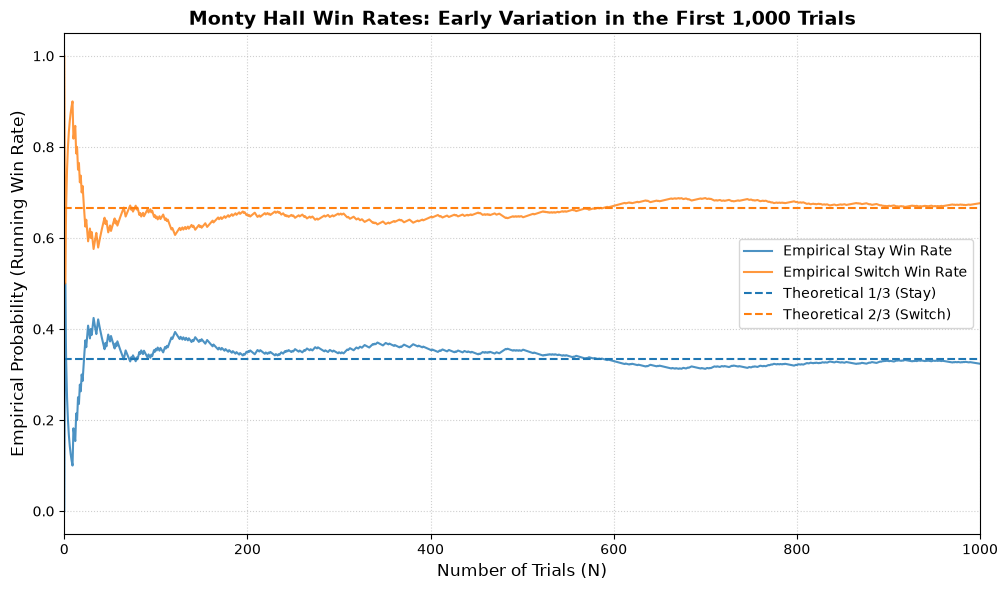

In [4]:
# ---------------------------------------------------------------
# Run the simulation and visualize convergence (Frequentist View)
# ---------------------------------------------------------------

# Number of games to simulate
N = 200000   # A large number makes the convergence smooth (Law of Large Numbers)

# Run the simulation and ask to track running averages
# We use a fixed seed (42) for reproducible results
res = simulate_monty_hall(N, track_running=True, seed=42)

# Print final win rates to compare with theoretical probabilities
print(f"Total trials: {N}")
print(f"Final stay win rate:   {res['running_stay'][-1]:.4f}  (Expected 1/3 ≈ 0.3333)")
print(f"Final switch win rate: {res['running_switch'][-1]:.4f}  (Expected 2/3 ≈ 0.6667)")


# ---------------------------------------------------------------
# Plot the convergence of probabilities
# ---------------------------------------------------------------

plt.figure(figsize=(10, 6))

# Plot running averages over trials
plt.plot(res["running_stay"], label="Empirical Stay Win Rate", color='tab:blue', alpha=0.8)
plt.plot(res["running_switch"], label="Empirical Switch Win Rate", color='tab:orange', alpha=0.8)

# Add horizontal dashed lines for theoretical values (the true probabilities)
plt.axhline(1/3, linestyle="--", color="tab:blue", label="Theoretical 1/3 (Stay)")
plt.axhline(2/3, linestyle="--", color="tab:orange", label="Theoretical 2/3 (Switch)")

# Label the axes
plt.xlabel("Number of Trials (N)", fontsize=12)
plt.ylabel("Empirical Probability (Running Win Rate)", fontsize=12)

# Add a descriptive title
plt.title("Monty Hall Win Rates: Early Variation in the First 1,000 Trials", fontsize=14, fontweight='bold')

# Display legend and format nicely
plt.legend(loc='center right')
plt.grid(True, linestyle=':', alpha=0.6, axis='both')
plt.tight_layout()
plt.xlim(0, min(1000, N)) # Zoom in to show initial convergence
plt.show()

In [5]:
# Evaluate across increasing batch sizes to show approximation quality
batch_sizes = [100, 1000, 10000, 100000, 200000]
summary = []
for n in batch_sizes:
    r = simulate_monty_hall(n, seed=42)
    summary.append((n, r['stay_wins'] / n, r['switch_wins'] / n))
df = pd.DataFrame(summary, columns=['trials', 'stay_rate', 'switch_rate'])
df


,trials,stay_rate,switch_rate
0,100,0.370000,0.630000
1,1000,0.334000,0.666000
2,10000,0.336300,0.663700
3,100000,0.331200,0.668800
4,200000,0.335265,0.664735


## Two Probability Questions

The simulation and the Bayesian calculation are related, but they answer different questions

**Repeated simulation question**

> If I repeat this game many times using the same strategy, how often will I win?

**Bayesian question**

> Given the door I chose and the specific door the host opened, how should I update the probability that the car is behind each remaining door?

We first use repeated simulation to study long-run win frequencies. We then use Bayes' theorem to reason directly about the probability of each car location after observing the host's action

Under the classical Monty Hall rules, both calculations support the same action: switch


## Part 2: 🧠 Bayesian Analysis (Updating Beliefs)

The **Bayesian** approach treats probability as a degree of belief and updates that belief after observing specific evidence

Here, the informative evidence is **which door the host opened**, together with the host's known decision rule. Merely observing that a goat was revealed is not informative because the host always reveals a goat under the classical rules

---

### 📝 Key Definitions

Let:

- **C**: Random variable for the door with the **car**, where $C \in \{1, 2, 3\}$. This is the hypothesis about the actual car location
- **c**: A specific door number, such as $c=1$ or $c=3$. This is one possible value of $C$
- **D**: The door the player initially picked. In the worked example, $D=1$
- **H**: The specific door opened by the host. In the worked example, $H=3$

We want the posterior probability of the car's location after observing the host's specific action and knowing the initial pick:

### 🔬 Bayes' Theorem

$$
P(C=c \mid H,D) = \frac{P(H \mid C=c,D)\,P(C=c \mid D)}{P(H \mid D)}
$$

The prior is written as $P(C=c \mid D)$ because the player's initial choice is known. The player chooses independently of the randomly located car, so:

$$
P(C=c \mid D) = P(C=c) = \frac{1}{3}
$$

This is why the familiar $1/3$ prior is still correct here

| Formula part | Name | What it asks | Role in the update |
|:---:|:---|:---|:---|
| $P(H \mid C=c,D)$ | **Likelihood** | If the car were at door $c$, how likely would the host be to open door $H$? | Measures how well the hypothesis $C=c$ explains the observed host action |
| $P(C=c \mid D)$ | **Prior** | Before the host opens a door, how likely is the car to be at door $c$ given the initial pick? | The initial belief, which is $1/3$ for each door |
| $P(H \mid D)$ | **Evidence** | What is the total probability of seeing the host open door $H$, given the initial pick? | The normalizing constant that makes the posterior probabilities sum to 1 |
| $P(C=c \mid H,D)$ | **Posterior** | After seeing the host open door $H$, how likely is the car to be at door $c$? | The updated belief used to choose stay or switch |

The evidence is the total of the likelihood times prior for all possible car locations:

$$
P(H \mid D) = \sum_{c' \in \{1,2,3\}} P(H \mid C=c',D)\,P(C=c' \mid D)
$$

---

### 🚪 Applying Bayes' Theorem: The Example

Let's fix the scenario:

1. **Initial pick**: You choose **Door 1**, so $D=1$
2. **Host's action**: The host opens **Door 3**, so $H=3$

The evidence is the specific action $H=3$, interpreted using the host's rules. It is not simply the fact that a goat was revealed

#### 1. Prior probability, $P(C=c \mid D=1)$

The car is still equally likely to be behind any door before we use the host's action:

$$
P(C=1 \mid D=1) = P(C=2 \mid D=1) = P(C=3 \mid D=1) = \frac{1}{3}
$$

#### 2. Likelihood, $P(H=3 \mid C=c,D=1)$

For each row, ask: **If the car were actually here, how likely would I be to observe the host opening Door 3?**

| Car location ($C$) | Likelihood $P(H=3 \mid C,D=1)$ | Why the host behaves this way | Unnormalized contribution $P(H=3 \mid C,D=1)P(C \mid D=1)$ |
|:---:|:---:|:---|:---:|
| **$C=1$** | $1/2$ | The host can open Door 2 or Door 3 and chooses randomly | $(1/2)(1/3)=1/6$ |
| **$C=2$** | $1$ | The host must open Door 3 because Door 2 has the car | $(1)(1/3)=1/3$ |
| **$C=3$** | $0$ | The host cannot open Door 3 because it has the car | $(0)(1/3)=0$ |

The three unnormalized posterior contributions are:

$$
\begin{aligned}
(1/2)(1/3) &= 1/6 \\
(1)(1/3) &= 1/3 \\
(0)(1/3) &= 0
\end{aligned}
$$

They are called **unnormalized** because they do not yet add up to 1

#### 3. Posterior probability, $P(C=c \mid H=3,D=1)$

First calculate the total evidence:

$$
P(H=3 \mid D=1) = 1/6 + 1/3 + 0 = 1/2
$$

Now divide each unnormalized contribution by that total:

$$
P(C=1 \mid H=3,D=1) = \frac{1/6}{1/2} = \frac{1}{3}
$$

$$
P(C=2 \mid H=3,D=1) = \frac{1/3}{1/2} = \frac{2}{3}
$$

$$
P(C=3 \mid H=3,D=1) = \frac{0}{1/2} = 0
$$

### Why the host's rule matters

These results assume that the host knows where the car is, never opens the player's door, never reveals the car, always offers the switch, and chooses randomly between the two goat doors when both are available

Bayes' theorem needs $P(H \mid C,D)$, so changing the host's behaviour changes the likelihood and can change the posterior after we observe a specific door

### **Conclusion**

After observing the specific action $H=3$, the original door still has probability $1/3$ and Door 2 has probability $2/3$. The Bayesian calculation therefore says to switch


## 💻 Interactive Bayesian Visualization

The code below implements the exact calculations from the previous section for any valid player pick and host action selected with the dropdowns

1. **Prior $P(C)$**: The initial $1/3$ belief for every door
2. **Likelihood × Prior, unnormalized posterior contribution**: The likelihood of the host's specific action multiplied by the prior for each possible car location
3. **Posterior $P(C \mid H,D)$**: The final probability after normalization

Normalization divides each unnormalized contribution by their total, $P(H \mid D)$

The host's rule is enforced automatically, so the host cannot open the door chosen by the player


In [6]:
# ---------- Core math ----------
def likelihood_vector_classic(D_idx: int, H_idx: int) -> np.ndarray:
    """L[c] = P(H | C=c, D) for the classic host who never opens D, never reveals car, randomizes if two goats remain"""
    if H_idx == D_idx:
        raise ValueError("Host cannot open the player's chosen door")
    doors = {0, 1, 2}
    L = np.zeros(3, dtype=float)
    for c in range(3):
        if c == D_idx:
            # HYPOTHESIS: Car is at the Picked Door (C=D). Host must randomize (0.5 chance of opening H).
            L[c] = 0.5
        else:
            # HYPOTHESIS: Car is NOT at the Picked Door (C!=D). Host is forced to open one specific door.
            forced = sorted(doors - {D_idx, c})[0]
            L[c] = 1.0 if H_idx == forced else 0.0
    return L

def bayes_posterior(prior: np.ndarray, like: np.ndarray):
    """
    Applies Bayes' theorem to find the Posterior probability.
    Returns: unnormalized contribution, posterior, and evidence (Z).
    """
    un = prior * like
    Z = float(un.sum())
    if Z == 0:
        raise ValueError("Zero evidence under supplied prior and likelihood")
    return un, un / Z, Z

# ---------- Visualization Helpers ----------
def door_schematic(ax, D_idx: int, H_idx: int):
    """
    Draws the door scenario schematic.
    Blue = picked door, Red = host opens, Orange = remaining closed.
    """
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 1)
    ax.axis("off")
    other_closed = sorted({0, 1, 2} - {D_idx, H_idx})[0]
    
    # Define colors based on the role in the scenario:
    colors = ["white"] * 3
    colors[D_idx] = "tab:blue"    # Picked Door (Stay)
    colors[H_idx] = "tab:red"     # Host Opens Door (Eliminated)
    colors[other_closed] = "tab:orange" # Other Closed Door (Switch)

    # Draw doors and labels
    for i in range(3):
        rect = plt.Rectangle((i + 0.05, 0.2), 0.9, 0.6, facecolor=colors[i], alpha=0.8)
        ax.add_patch(rect)
        ax.text(i + 0.5, 0.5, f"Door {i+1}", ha="center", va="center", fontsize=12, color="white", weight="bold")
    
    ax.text(D_idx + 0.5, 0.07, "Initial Pick", color="tab:blue", ha="center", fontsize=10, weight="bold")
    ax.text(H_idx + 0.5, 0.07, "Host Opens", color="tab:red", ha="center", fontsize=10, weight="bold")
    ax.text(other_closed + 0.5, 0.07, "Switch Target", color="tab:orange", ha="center", fontsize=10, weight="bold")

def plot_update(D_num: int, H_num: int, message_widget: w.HTML, out: w.Output):
    """Compute and render the full 3-step update visualization."""
    D_idx, H_idx = D_num - 1, H_num - 1
    prior = np.array([1/3, 1/3, 1/3], dtype=float)

    try:
        like = likelihood_vector_classic(D_idx, H_idx)
        contrib, post, evidence = bayes_posterior(prior, like)
        other_closed = sorted({0, 1, 2} - {D_idx, H_idx})[0]
        
        # Labels for the bar charts
        labels = [f"Car at Door {i+1}" for i in [0,1,2]]
        
        # Define bar colors: Blue (Stay/Picked), Orange (Switch/Other Closed), Red (Eliminated/Host Opened)
        bar_colors = ["white"] * 3
        bar_colors[D_idx] = "tab:blue"
        bar_colors[other_closed] = "tab:orange"
        bar_colors[H_idx] = "tab:red"

        with out:
            clear_output(wait=True)
            # Text summary
            print(f"Scenario: Player picks Door {D_num}, Host opens Door {H_num}")
            print("-" * 60)
            print(f"P(Stay)   = P(Car at Door {D_num}) = {post[D_idx]:.4f} (1/3)")
            print(f"P(Switch) = P(Car at Door {other_closed+1}) = {post[other_closed]:.4f} (2/3)")
            print(f"Evidence P(H | D) = {evidence:.4f}")
            print("-" * 60)
            
            # --- Figure Layout ---
            fig = plt.figure(figsize=(15, 6))
            # GridSpec creates two rows: one for the schematic, one for the 3 plots
            gs = fig.add_gridspec(2, 3, height_ratios=[0.5, 1.2], hspace=0.35)

            # Row 1: Door Schematic
            ax0 = fig.add_subplot(gs[0, :])
            door_schematic(ax0, D_idx, H_idx)

            # Row 2, Col 1: Prior P(C)
            ax1 = fig.add_subplot(gs[1, 0])
            b1 = ax1.bar(labels, prior, color=bar_colors)
            ax1.set_ylim(0, 1); 
            ax1.set_title("Step 1: Prior P(C) (Initial Belief)", fontsize=12, fontweight='bold'); 
            ax1.tick_params(axis="x", rotation=15, labelsize=9)
            for bar in b1: ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02, f"{bar.get_height():.3f}", ha="center", fontsize=9)

            # Row 2, Col 2: Unnormalized Contributions P(H|C) P(C)
            ax2 = fig.add_subplot(gs[1, 1])
            # Set y-limit to clearly show the zero contribution from the host's door
            max_contrib = max(contrib.max() * 1.25, 0.45) 
            b2 = ax2.bar(labels, contrib, color=bar_colors)
            ax2.set_ylim(0, max_contrib); 
            ax2.set_title("Step 2: Likelihood × Prior (Unnormalized Contribution)", fontsize=12, fontweight='bold'); 
            ax2.tick_params(axis="x", rotation=15, labelsize=9)
            for bar in b2:
                h = bar.get_height()
                if h > 1e-6:
                    ax2.text(bar.get_x()+bar.get_width()/2, h+0.02, f"{h:.3f}", ha="center", fontsize=9)
                else:
                    ax2.text(bar.get_x()+bar.get_width()/2, 0.01, f"{h:.3f}", ha="center", fontsize=9) # Show the zero clearly

            # Row 2, Col 3: Posterior P(C | H, D)
            ax3 = fig.add_subplot(gs[1, 2])
            b3 = ax3.bar(labels, post, color=bar_colors)
            ax3.set_ylim(0, 1); 
            ax3.set_title("Step 3: Posterior P(C | H, D) (Final Belief)", fontsize=12, fontweight='bold'); 
            ax3.tick_params(axis="x", rotation=15, labelsize=9)
            for bar in b3: ax3.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02, f"{bar.get_height():.3f}", ha="center", fontsize=9)

            plt.show()

    except ValueError as e:
        # Catch the intentional error when H=D before the guard corrects it
        message_widget.value = f"<span style='color:#d62728; font-weight:bold;'>Error: {e}. Host cannot open your selected door.</span>"

# ---------- UI wiring and Execution ----------
# Use Dropdown for clear options 1, 2, 3
pick = w.Dropdown(description="Player Pick (D)", options=[1,2,3], value=1)
host = w.Dropdown(description="Host Opens (H)", options=[2,3], value=3) 
msg  = w.HTML(value="", placeholder="messages")
out  = w.Output()

def on_pick_change(change):
    # Dynamically update host options to exclude the pick
    p = change["new"]
    new_options = [d for d in [1,2,3] if d != p]
    
    # Check if the host's current value is now illegal
    if host.value == p:
        host.value = new_options[0] # Set to the first legal option
        msg.value = f"<span style='color:#d62728;'>Host cannot open your door. Host's option adjusted to Door {host.value}.</span>"
    else:
        msg.value = ""
    host.options = new_options # Update the dropdown options

def on_any_change(_):
    # This function handles the main plotting on any dropdown value change
    plot_update(pick.value, host.value, msg, out)

# Observe changes
pick.observe(on_pick_change, names="value")
pick.observe(on_any_change, names="value")
host.observe(on_any_change, names="value")

# Initial Render to draw the default scenario
on_pick_change({"new": pick.value}) # Run the pick change handler once to set host options
on_any_change(None) # Render the plot

# Display UI
display(w.VBox([w.Label("Choose the player's initial door and the door opened by the host:"), w.HBox([pick, host]), msg, out]))